In [1]:
!pip install pyspark

In [3]:

import pandas as pd

file_name = "online_retail.xlsx"

sheet_1 = pd.read_excel(file_name, sheet_name=0)
sheet_2 = pd.read_excel(file_name, sheet_name=1)

df = pd.concat([sheet_1, sheet_2], ignore_index=True)

df.to_csv("/content/online_retail.csv", index=False)

print("Dataset combined successfully!")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print(df.head())


Dataset combined successfully!
Total rows: 1067371
Total columns: 8
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [4]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("EcommerceBigDataAnalysis") \
    .getOrCreate()

spark_df = spark.read.csv(
    "/content/online_retail.csv",
    header=True,
    inferSchema=True
)

print("Spark loaded the dataset!")

spark_df.printSchema()
spark_df.show(5, truncate=False)


Spark loaded the dataset!
root
 |-- Invoice: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- Price: double (nullable = true)
 |-- Customer ID: double (nullable = true)
 |-- Country: string (nullable = true)

+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|Customer ID|Country       |
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |13085.0    |United Kingdom|
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |13085.0    |United Kingdom|
|489434 |79323W   | WHITE CHERRY LIGHTS          

In [5]:
# 1. Check the total number of rows and columns
print("Total rows:", spark_df.count())
print("Total columns:", len(spark_df.columns))

# 2. Display column names
print("Column names:", spark_df.columns)

# 3. Check missing values in each column
from pyspark.sql.functions import col, sum, when

missing_values = spark_df.select([
    sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in spark_df.columns
])

missing_values.show(truncate=False)

# 4. Display basic statistics
spark_df.describe(
    "Quantity", "Price", "Customer ID"
).show()

Total rows: 1067371
Total columns: 8
Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
+-------+---------+-----------+--------+-----------+-----+-----------+-------+
|Invoice|StockCode|Description|Quantity|InvoiceDate|Price|Customer ID|Country|
+-------+---------+-----------+--------+-----------+-----+-----------+-------+
|0      |0        |4382       |0       |0          |0    |243007     |0      |
+-------+---------+-----------+--------+-----------+-----+-----------+-------+

+-------+------------------+------------------+------------------+
|summary|          Quantity|             Price|       Customer ID|
+-------+------------------+------------------+------------------+
|  count|           1067371|           1067371|            824364|
|   mean|   9.9388984711033| 4.649387727413342| 15324.63850435002|
| stddev|172.70579407675524|123.55305872146378|1697.4644503793263|
|    min|            -80995|         -53594.36|  

In [6]:
from pyspark.sql.functions import col, trim, upper

# Count cancellation invoices
print(
    "Cancellation invoices:",
    spark_df.filter(
        col("Invoice").startswith("C")
    ).count()
)

# Count invalid quantities
print(
    "Zero or negative quantities:",
    spark_df.filter(col("Quantity") <= 0).count()
)

# Count invalid prices
print(
    "Zero or negative prices:",
    spark_df.filter(col("Price") <= 0).count()
)

# Count missing customer IDs
print(
    "Missing customer IDs:",
    spark_df.filter(col("Customer ID").isNull()).count()
)

Cancellation invoices: 19494
Zero or negative quantities: 22950
Zero or negative prices: 6207
Missing customer IDs: 243007


In [7]:
clean_df = spark_df.filter(
    (~col("Invoice").startswith("C")) &
    (col("Quantity") > 0) &
    (col("Price") > 0) &
    col("Invoice").isNotNull() &
    col("StockCode").isNotNull() &
    col("InvoiceDate").isNotNull()
)

# Remove extra spaces from product descriptions
clean_df = clean_df.withColumn(
    "Description",
    trim(col("Description"))
)

# Calculate revenue for each transaction line
clean_df = clean_df.withColumn(
    "Revenue",
    col("Quantity") * col("Price")
)

print("Original rows:", spark_df.count())
print("Cleaned rows:", clean_df.count())

clean_df.show(5, truncate=False)

Original rows: 1067371
Cleaned rows: 1041670
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+------------------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|Customer ID|Country       |Revenue           |
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+------------------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |13085.0    |United Kingdom|83.4              |
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |13085.0    |United Kingdom|81.0              |
|489434 |79323W   |WHITE CHERRY LIGHTS                |12      |2009-12-01 07:45:00|6.75 |13085.0    |United Kingdom|81.0              |
|489434 |22041    |"RECORD FRAME 7"" SINGLE SIZE "    |48      |2009-12-01 07:45:00|2.1  |13085.0    |United Kingdom|100.800000000000

In [8]:
from pyspark.sql.functions import col

print(
    "Missing descriptions after cleaning:",
    clean_df.filter(
        col("Description").isNull() |
        (col("Description") == "")
    ).count()
)

print(
    "Missing countries after cleaning:",
    clean_df.filter(
        col("Country").isNull() |
        (col("Country") == "")
    ).count()
)

print(
    "Distinct invoices:",
    clean_df.select("Invoice").distinct().count()
)

print(
    "Distinct products:",
    clean_df.select("StockCode").distinct().count()
)

Missing descriptions after cleaning: 0
Missing countries after cleaning: 0
Distinct invoices: 40077
Distinct products: 4917


In [9]:
from pyspark.sql.functions import (
    sum, countDistinct, avg, round, date_format, col
)

# Overall sales metrics
sales_summary = clean_df.agg(
    round(sum("Revenue"), 2).alias("Total_Revenue"),
    sum("Quantity").alias("Total_Units_Sold"),
    countDistinct("Invoice").alias("Total_Invoices"),
    round(avg("Revenue"), 2).alias("Average_Line_Revenue")
)

sales_summary.show(truncate=False)

+-------------+----------------+--------------+--------------------+
|Total_Revenue|Total_Units_Sold|Total_Invoices|Average_Line_Revenue|
+-------------+----------------+--------------+--------------------+
|2.097259457E7|11420305        |40077         |20.13               |
+-------------+----------------+--------------+--------------------+



In [10]:
monthly_sales = clean_df.groupBy(
    date_format("InvoiceDate", "yyyy-MM").alias("Month")
).agg(
    round(sum("Revenue"), 2).alias("Revenue"),
    countDistinct("Invoice").alias("Invoices")
).orderBy("Month")

monthly_sales.show(30, truncate=False)

+-------+----------+--------+
|Month  |Revenue   |Invoices|
+-------+----------+--------+
|2009-12|825685.76 |1682    |
|2010-01|652708.5  |1105    |
|2010-02|553339.74 |1201    |
|2010-03|833570.13 |1681    |
|2010-04|681528.99 |1462    |
|2010-05|659858.86 |1500    |
|2010-06|752270.14 |1645    |
|2010-07|650712.94 |1529    |
|2010-08|697274.91 |1425    |
|2010-09|924333.01 |1839    |
|2010-10|1165483.91|2301    |
|2010-11|1470272.48|2747    |
|2010-12|1262598.79|1559    |
|2011-01|691364.56 |1086    |
|2011-02|523631.89 |1100    |
|2011-03|717639.36 |1454    |
|2011-04|537808.62 |1246    |
|2011-05|770536.02 |1681    |
|2011-06|761739.9  |1533    |
|2011-07|719221.19 |1475    |
|2011-08|759138.38 |1361    |
|2011-09|1058590.17|1837    |
|2011-10|1154979.3 |2040    |
|2011-11|1509496.33|2769    |
|2011-12|638810.68 |819     |
+-------+----------+--------+



In [11]:
top_products = clean_df.groupBy(
    "StockCode", "Description"
).agg(
    sum("Quantity").alias("Units_Sold"),
    round(sum("Revenue"), 2).alias("Total_Revenue")
).orderBy(
    col("Total_Revenue").desc()
)

top_products.show(10, truncate=False)

+---------+----------------------------------+----------+-------------+
|StockCode|Description                       |Units_Sold|Total_Revenue|
+---------+----------------------------------+----------+-------------+
|22423    |REGENCY CAKESTAND 3 TIER          |27577     |344563.25    |
|M        |Manual                            |10050     |340716.28    |
|DOT      |DOTCOM POSTAGE                    |1436      |322657.48    |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|96086     |262931.16    |
|23843    |PAPER CRAFT , LITTLE BIRDIE       |80995     |168469.6     |
|47566    |PARTY BUNTING                     |28378     |149187.05    |
|85099B   |JUMBO BAG RED RETROSPOT           |78860     |148823.92    |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |81809     |132187.92    |
|POST     |POSTAGE                           |5461      |127597.42    |
|22086    |PAPER CHAIN KIT 50'S CHRISTMAS    |36581     |123141.54    |
+---------+----------------------------------+----------+-------

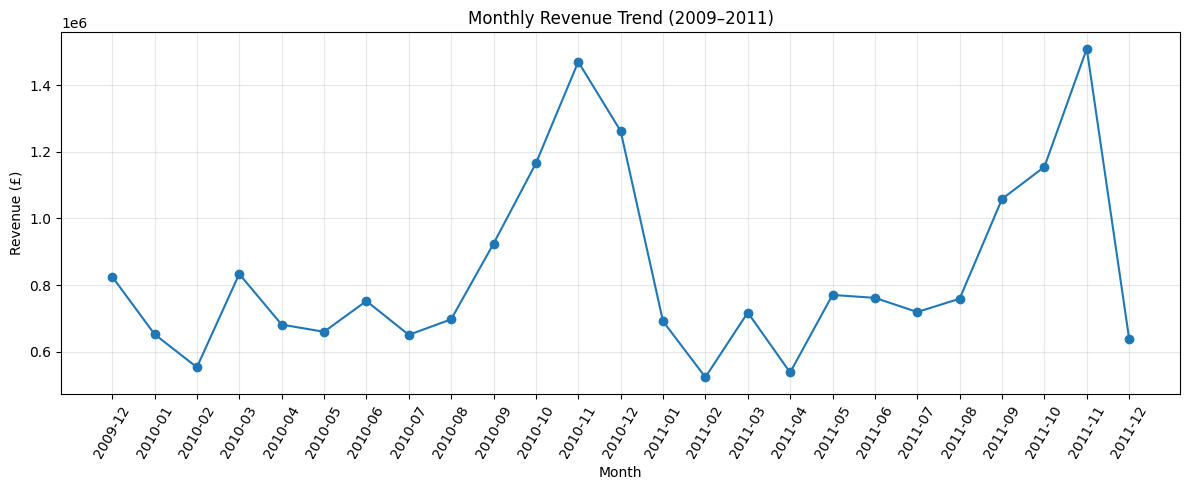

In [12]:
import matplotlib.pyplot as plt

# Convert the aggregated Spark result to Pandas
monthly_pd = monthly_sales.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_pd["Month"],
    monthly_pd["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend (2009–2011)")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
from pyspark.sql.functions import col, sum, round

product_sales = clean_df.filter(
    ~col("StockCode").isin("M", "DOT", "POST")
)

top_products_clean = product_sales.groupBy(
    "StockCode", "Description"
).agg(
    sum("Quantity").alias("Units_Sold"),
    round(sum("Revenue"), 2).alias("Total_Revenue")
).orderBy(
    col("Total_Revenue").desc()
)

top_products_clean.show(10, truncate=False)

+---------+-----------------------------------+----------+-------------+
|StockCode|Description                        |Units_Sold|Total_Revenue|
+---------+-----------------------------------+----------+-------------+
|22423    |REGENCY CAKESTAND 3 TIER           |27577     |344563.25    |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER |96086     |262931.16    |
|23843    |PAPER CRAFT , LITTLE BIRDIE        |80995     |168469.6     |
|47566    |PARTY BUNTING                      |28378     |149187.05    |
|85099B   |JUMBO BAG RED RETROSPOT            |78860     |148823.92    |
|84879    |ASSORTED COLOUR BIRD ORNAMENT      |81809     |132187.92    |
|22086    |PAPER CHAIN KIT 50'S CHRISTMAS     |36581     |123141.54    |
|79321    |CHILLI LIGHTS                      |16840     |85489.91     |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR     |78033     |81700.92     |
|84347    |ROTATING SILVER ANGELS T-LIGHT HLDR|32525     |74448.92     |
+---------+-----------------------------------+----

In [14]:
country_sales = clean_df.groupBy("Country").agg(
    round(sum("Revenue"), 2).alias("Total_Revenue"),
    sum("Quantity").alias("Units_Sold"),
    countDistinct("Invoice").alias("Total_Invoices")
).orderBy(
    col("Total_Revenue").desc()
)

country_sales.show(10, truncate=False)

+--------------+-------------+----------+--------------+
|Country       |Total_Revenue|Units_Sold|Total_Invoices|
+--------------+-------------+----------+--------------+
|United Kingdom|1.787097778E7|9383244   |36535         |
|EIRE          |664431.78    |340289    |626           |
|Netherlands   |554232.34    |383977    |228           |
|Germany       |431262.46    |227983    |789           |
|France        |356944.6     |275287    |622           |
|Australia     |169968.11    |104090    |95            |
|Spain         |109178.53    |50796     |154           |
|Switzerland   |101011.29    |52884     |93            |
|Sweden        |91903.72     |88650     |105           |
|Denmark       |69862.19     |237925    |43            |
+--------------+-------------+----------+--------------+
only showing top 10 rows


In [15]:
from pyspark.sql.functions import (
    col, sum, countDistinct, round, avg
)

customer_df = clean_df.filter(
    col("Customer ID").isNotNull()
)

customer_sales = customer_df.groupBy(
    "Customer ID"
).agg(
    round(sum("Revenue"), 2).alias("Total_Spending"),
    countDistinct("Invoice").alias("Total_Orders"),
    sum("Quantity").alias("Total_Units")
).orderBy(
    col("Total_Spending").desc()
)

customer_sales.show(10, truncate=False)

+-----------+--------------+------------+-----------+
|Customer ID|Total_Spending|Total_Orders|Total_Units|
+-----------+--------------+------------+-----------+
|18102.0    |608821.65     |145         |188340     |
|14646.0    |528602.52     |151         |367193     |
|14156.0    |313946.37     |156         |165992     |
|14911.0    |295972.63     |398         |149987     |
|17450.0    |246973.09     |51          |84720      |
|13694.0    |196482.81     |143         |189205     |
|17511.0    |175603.55     |60          |119656     |
|16446.0    |168472.5      |2           |80997      |
|16684.0    |147142.77     |55          |104810     |
|12415.0    |144458.37     |28          |91447      |
+-----------+--------------+------------+-----------+
only showing top 10 rows


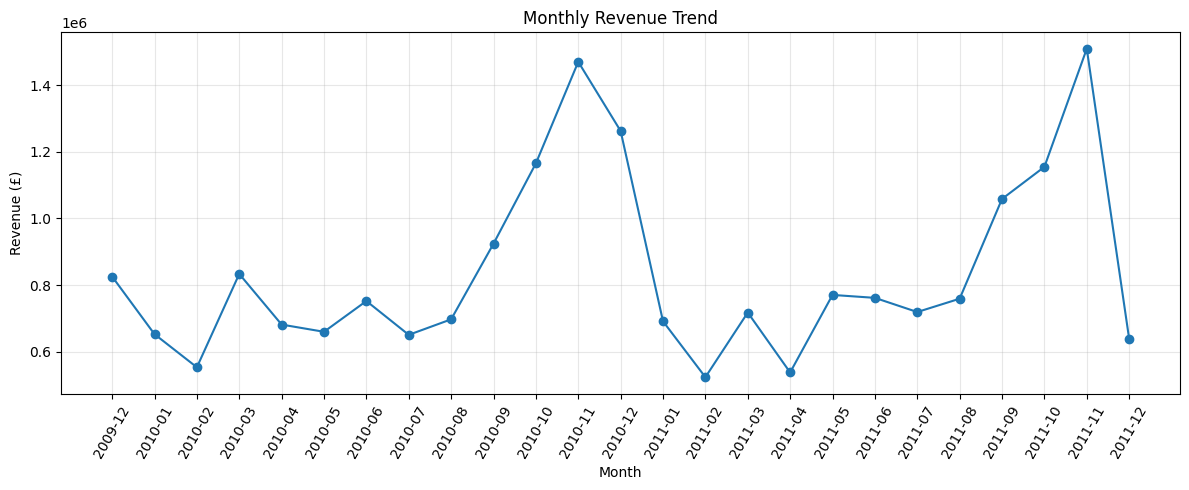

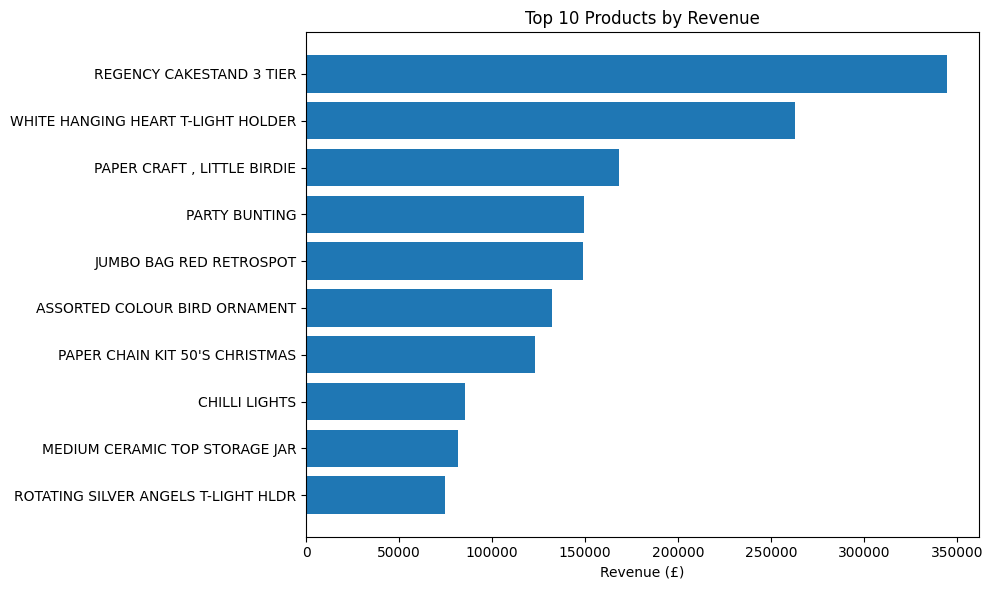

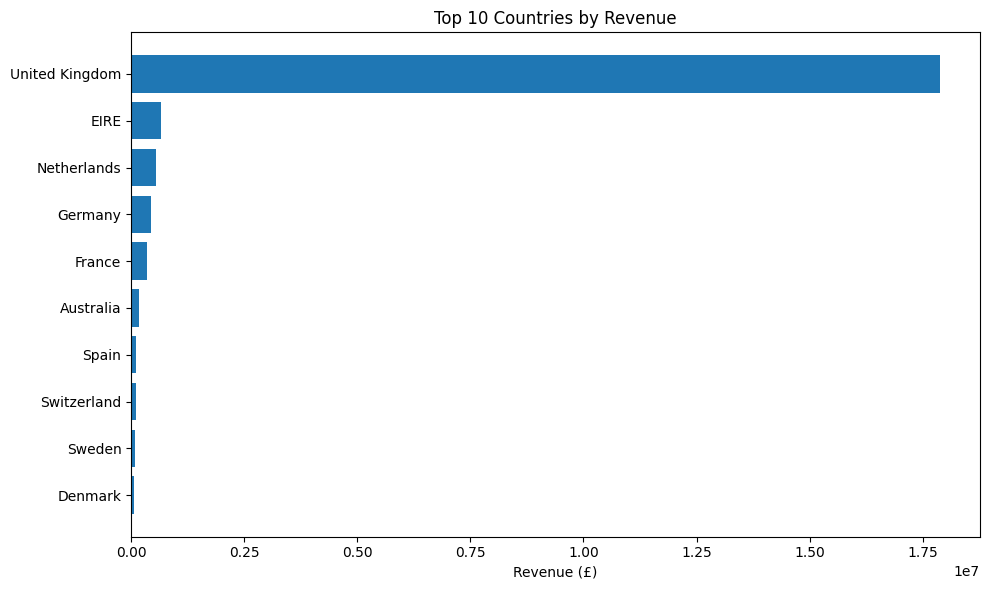

In [16]:

import matplotlib.pyplot as plt

# 1. Monthly revenue trend
monthly_pd = monthly_sales.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(monthly_pd["Month"], monthly_pd["Revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Top 10 products by revenue
products_pd = top_products_clean.limit(10).toPandas()
products_pd = products_pd.sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))
plt.barh(products_pd["Description"], products_pd["Total_Revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()


# 3. Top 10 countries by revenue
countries_pd = country_sales.limit(10).toPandas()
countries_pd = countries_pd.sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))
plt.barh(countries_pd["Country"], countries_pd["Total_Revenue"])
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

In [17]:
from pyspark.sql.functions import sum, col, desc

# Check the current number of partitions
print("Original partitions:", clean_df.rdd.getNumPartitions())

# Repartition the dataset using Country
partitioned_df = clean_df.repartition(4, "Country")

print("New partitions:", partitioned_df.rdd.getNumPartitions())

# Perform a Spark aggregation
country_summary = partitioned_df.groupBy("Country").agg(
    sum("Revenue").alias("Total_Revenue")
).orderBy(desc("Total_Revenue"))

# Display the execution plan
country_summary.explain("formatted")

# Execute the analysis
country_summary.show(5, truncate=False)

Original partitions: 2
New partitions: 4
== Physical Plan ==
AdaptiveSparkPlan (9)
+- Sort (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- HashAggregate (5)
            +- Exchange (4)
               +- Project (3)
                  +- Filter (2)
                     +- Scan csv  (1)


(1) Scan csv 
Output [6]: [Invoice#17, StockCode#18, Quantity#20, InvoiceDate#21, Price#22, Country#24]
Batched: false
Location: InMemoryFileIndex [file:/content/online_retail.csv]
PushedFilters: [IsNotNull(Quantity), IsNotNull(Price), Not(StringStartsWith(Invoice,C)), GreaterThan(Quantity,0), GreaterThan(Price,0.0), IsNotNull(Invoice), IsNotNull(StockCode), IsNotNull(InvoiceDate)]
ReadSchema: struct<Invoice:string,StockCode:string,Quantity:int,InvoiceDate:timestamp,Price:double,Country:string>

(2) Filter
Input [6]: [Invoice#17, StockCode#18, Quantity#20, InvoiceDate#21, Price#22, Country#24]
Condition : (((((((isnotnull(Quantity#20) AND isnotnull(Price#22)) AND NOT StartsWith(Invoice#17, 

In [18]:
from pyspark.sql.functions import sum, count

clean_df.agg(
    count("*").alias("Cleaned_Records"),
    sum("Revenue").alias("Total_Revenue")
).show()

+---------------+-------------------+
|Cleaned_Records|      Total_Revenue|
+---------------+-------------------+
|        1041670|2.097259456800223E7|
+---------------+-------------------+

